In [28]:
# SECTION 1: IMPORTING LIBRARIES

import os
import sys
import math
import json
from typing import List, Dict, Optional, Tuple

# For data handling
import pandas as pd
import numpy as np

# for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# For preparing and splitting the dataset
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# For model trainind and testing
from sklearn.linear_model import LogisticRegression

# Metrics to use evaluate model performance
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# To polish graphs and make look cleaner
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [29]:
# SECTION 2: LOADING THE CLEANED DATASET

df = pd.read_csv("pnw_training_corrected.csv")

# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display the first five rows
display(df.head())

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check the data types and missing values
print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))


Dataset dimensions: (38579, 22)


,event_id,label,source_latitude_deg,source_longitude_deg,preferred_source_magnitude,source_depth_km,local_hour_sin,local_hour_cos,weekend,cb_crest_factor,...,nb_log10_sh_sz_rms_ratio_4_8hz,nb_envelope_rise_10_90_s_2_10hz,nb_envelope_excess_kurtosis_2_10hz,nb_log10_psd_power_1_5_over_5_15hz,geographic_fold,nb_log10_pz_sh_rms_ratio_4_8hz__n_stations,nb_log10_sh_sz_rms_ratio_4_8hz__n_stations,nb_envelope_rise_10_90_s_2_10hz__n_stations,nb_envelope_excess_kurtosis_2_10hz__n_stations,nb_log10_psd_power_1_5_over_5_15hz__n_stations
0,uw10547793,0,42.022,-122.097,1.5,6.319,-0.992810,0.119704,0,12.179417,...,1.040345,4.07,10.797078,-0.969816,4,1,1,1,1,1
1,uw10547878,0,42.105,-124.375,2.4,30.687,-0.316339,0.948646,1,5.191879,...,0.480488,1.45,4.102076,0.431430,2,1,1,1,1,1
2,uw10549468,0,47.612,-121.956,0.7,17.861,0.604831,-0.796354,0,5.542710,...,0.260246,4.63,1.901415,-0.143798,5,1,1,1,1,1
3,uw10549578,0,48.459,-119.543,2.9,2.684,0.536379,0.843977,0,6.678193,...,0.300007,14.50,3.993996,-0.263133,1,1,1,1,1,1
4,uw10549668,0,48.413,-122.286,3.0,18.139,0.187881,-0.982192,0,8.095458,...,0.316037,12.15,2.513362,0.090698,3,1,1,1,1,1



Column names:
['event_id', 'label', 'source_latitude_deg', 'source_longitude_deg', 'preferred_source_magnitude', 'source_depth_km', 'local_hour_sin', 'local_hour_cos', 'weekend', 'cb_crest_factor', 'cb_spectral_entropy', 'nb_log10_pz_sh_rms_ratio_4_8hz', 'nb_log10_sh_sz_rms_ratio_4_8hz', 'nb_envelope_rise_10_90_s_2_10hz', 'nb_envelope_excess_kurtosis_2_10hz', 'nb_log10_psd_power_1_5_over_5_15hz', 'geographic_fold', 'nb_log10_pz_sh_rms_ratio_4_8hz__n_stations', 'nb_log10_sh_sz_rms_ratio_4_8hz__n_stations', 'nb_envelope_rise_10_90_s_2_10hz__n_stations', 'nb_envelope_excess_kurtosis_2_10hz__n_stations', 'nb_log10_psd_power_1_5_over_5_15hz__n_stations']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 38579 entries, 0 to 38578
Data columns (total 22 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   event_id                                        38579 non-null

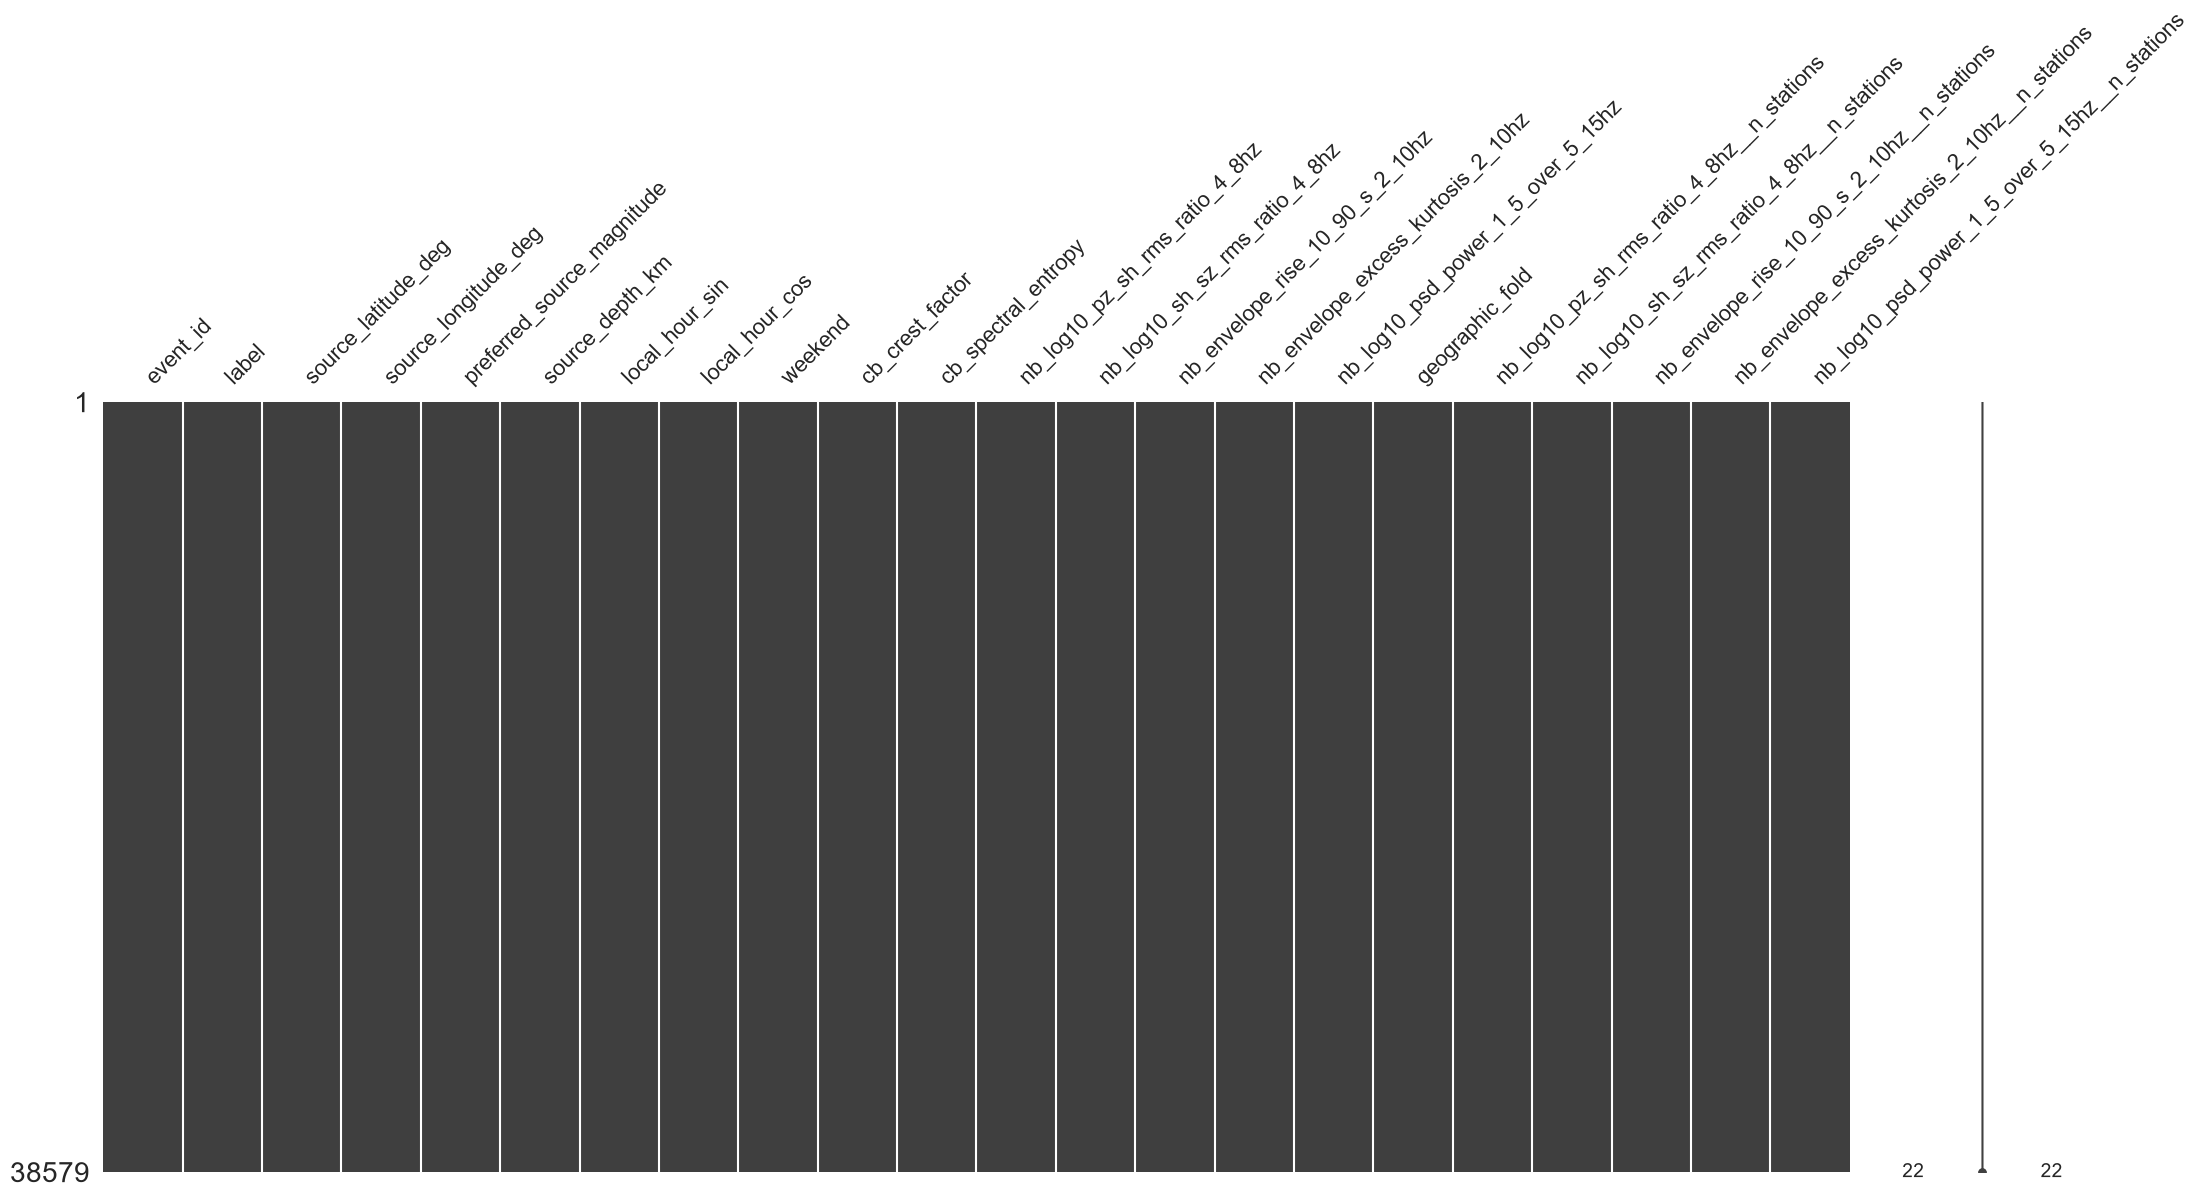

In [30]:
# VISUALIZING MISSINGNESS
msno.matrix(df)
plt.show()

In [31]:
# SECTION 3: CHECKING LABELS AND GROUPING

# Check how earthquakes and explosions are encoded
print("EVENT LABEL COUNTS:")
print(df["label"].value_counts().sort_index())

print("\nEVENT LABEL PROPORTIONS:")
print(df["label"].value_counts(normalize=True).sort_index())

# Check how many geographic groups we have
print("\nGEOGRAPHIC FOLD COUNTS:")
print(df["geographic_fold"].value_counts().sort_index())

print("\nNumber of geographic folds:",
      df["geographic_fold"].nunique())

# Check whether event IDs are unique
print("\nUNIQUE EVENT IDS:",
      df["event_id"].nunique())

print("\nDUPLICATE EVENT IDS:",
      df["event_id"].duplicated().sum())

# Check whether events within each geographic fold
# contain both earthquake and explosion labels
print("\nLABEL DISTRIBUTION BY GEOGRAPHIC FOLD:")
print(pd.crosstab(df["geographic_fold"], df["label"]))


EVENT LABEL COUNTS:
label
0    32912
1     5667
Name: count, dtype: int64

EVENT LABEL PROPORTIONS:
label
0    0.853107
1    0.146893
Name: proportion, dtype: float64

GEOGRAPHIC FOLD COUNTS:
geographic_fold
1    7724
2    7719
3    7712
4    7713
5    7711
Name: count, dtype: int64

Number of geographic folds: 5

UNIQUE EVENT IDS: 38579

DUPLICATE EVENT IDS: 0

LABEL DISTRIBUTION BY GEOGRAPHIC FOLD:
label               0     1
geographic_fold            
1                6586  1138
2                6584  1135
3                6581  1131
4                6581  1132
5                6580  1131


In [32]:
# SECTION 4: SELECTING THE FEATURES

# The column the model will predict
target = "label"

# Catalog information, excluding depth
catalog_features = [
    "source_latitude_deg",
    "source_longitude_deg",
    "preferred_source_magnitude",
    "local_hour_sin",
    "local_hour_cos",
    "weekend"
]

# Depth is kept separate to measure its contribution
depth_feature = ["source_depth_km"]

# Waveform measurements
waveform_features = [
    "cb_crest_factor",
    "cb_spectral_entropy",
    "nb_log10_pz_sh_rms_ratio_4_8hz",
    "nb_log10_sh_sz_rms_ratio_4_8hz",
    "nb_envelope_rise_10_90_s_2_10hz",
    "nb_envelope_excess_kurtosis_2_10hz",
    "nb_log10_psd_power_1_5_over_5_15hz"
]

# Four experiments
experiments = {
    "A - Catalog only": catalog_features,

    "B - Catalog + Waveforms":
        catalog_features + waveform_features,

    "C - Catalog + Depth":
        catalog_features + depth_feature,

    "D - Catalog + Depth + Waveforms":
        catalog_features + depth_feature + waveform_features
}

# Checking that all selected columns exist
for name, features in experiments.items():
    missing = [col for col in features if col not in df.columns]

    if missing:
        raise ValueError(f"{name} has missing columns: {missing}")

    print(f"{name}: {len(features)} features")

print("\nFeature selection complete!")


A - Catalog only: 6 features
B - Catalog + Waveforms: 13 features
C - Catalog + Depth: 7 features
D - Catalog + Depth + Waveforms: 14 features

Feature selection complete!


In [33]:
# SECTION 5: TRAINING THE LOGISTIC REGRESSION MODEL

from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Separate the target, predictors and geographic groups
y = df[target]
groups = df["geographic_fold"]

# Five-fold geographic cross-validation
cv = GroupKFold(n_splits=5)

# Store results and predictions
results = []
all_predictions = {}

# Repeat the experiment for each feature combination
for experiment_name, features in experiments.items():

    print("\nRunning:", experiment_name)

    # Select the features for this experiment
    X = df[features]

    # Store predictions for every event
    oof_predictions = np.zeros(len(df))

    fold_scores = []

    # Train on four folds and test on the remaining fold
    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X, y, groups), start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # Prepare the data and train logistic regression
        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(
                max_iter=2000,
                class_weight=None,
                random_state=42
            ))
        ])

        model.fit(X_train, y_train)

        # Predict explosion probabilities
        probabilities = model.predict_proba(X_test)[:, 1]

        # Save predictions for later evaluation
        oof_predictions[test_idx] = probabilities

        # Average precision for this geographic fold
        fold_ap = average_precision_score(
            y_test, probabilities
        )

        fold_scores.append(fold_ap)

        print(f"Fold {fold}: Average precision = {fold_ap:.4f}")

    # Convert probabilities into predictions
    # Threshold = 0.5 for this initial comparison
    predicted_labels = (oof_predictions >= 0.5).astype(int)

    # Calculate overall performance using all out-of-fold predictions
    ap = average_precision_score(y, oof_predictions)
    precision = precision_score(
        y, predicted_labels, zero_division=0
    )
    recall = recall_score(
        y, predicted_labels, zero_division=0
    )
    f1 = f1_score(
        y, predicted_labels, zero_division=0
    )
    roc_auc = roc_auc_score(y, oof_predictions)

    # Save the experiment results
    results.append({
        "Experiment": experiment_name,
        "Average Precision": ap,
        "Mean Fold AP": np.mean(fold_scores),
        "Fold AP Std": np.std(fold_scores),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc
    })

    all_predictions[experiment_name] = oof_predictions

# Create a results table
results_df = pd.DataFrame(results)

print("\n========== LOGISTIC REGRESSION RESULTS ==========")
display(results_df.round(4))



Running: A - Catalog only
Fold 1: Average precision = 0.5626
Fold 2: Average precision = 0.4307
Fold 3: Average precision = 0.4539
Fold 4: Average precision = 0.4354
Fold 5: Average precision = 0.4740

Running: B - Catalog + Waveforms
Fold 1: Average precision = 0.7207
Fold 2: Average precision = 0.7632
Fold 3: Average precision = 0.8324
Fold 4: Average precision = 0.8605
Fold 5: Average precision = 0.8549

Running: C - Catalog + Depth
Fold 1: Average precision = 0.7988
Fold 2: Average precision = 0.7880
Fold 3: Average precision = 0.8709
Fold 4: Average precision = 0.8372
Fold 5: Average precision = 0.8863

Running: D - Catalog + Depth + Waveforms
Fold 1: Average precision = 0.7667
Fold 2: Average precision = 0.8604
Fold 3: Average precision = 0.9000
Fold 4: Average precision = 0.9102
Fold 5: Average precision = 0.9256

========== LOGISTIC REGRESSION RESULTS ==========


,Experiment,Average Precision,Mean Fold AP,Fold AP Std,Precision,Recall,F1 Score,ROC AUC
0,A - Catalog only,0.4663,0.4713,0.0481,0.5270,0.2755,0.3618,0.8854
1,B - Catalog + Waveforms,0.7993,0.8063,0.0551,0.8206,0.7233,0.7689,0.9686
2,C - Catalog + Depth,0.8294,0.8362,0.0385,0.8210,0.8537,0.8370,0.9738
3,D - Catalog + Depth + Waveforms,0.8620,0.8726,0.0572,0.8704,0.8666,0.8685,0.9833


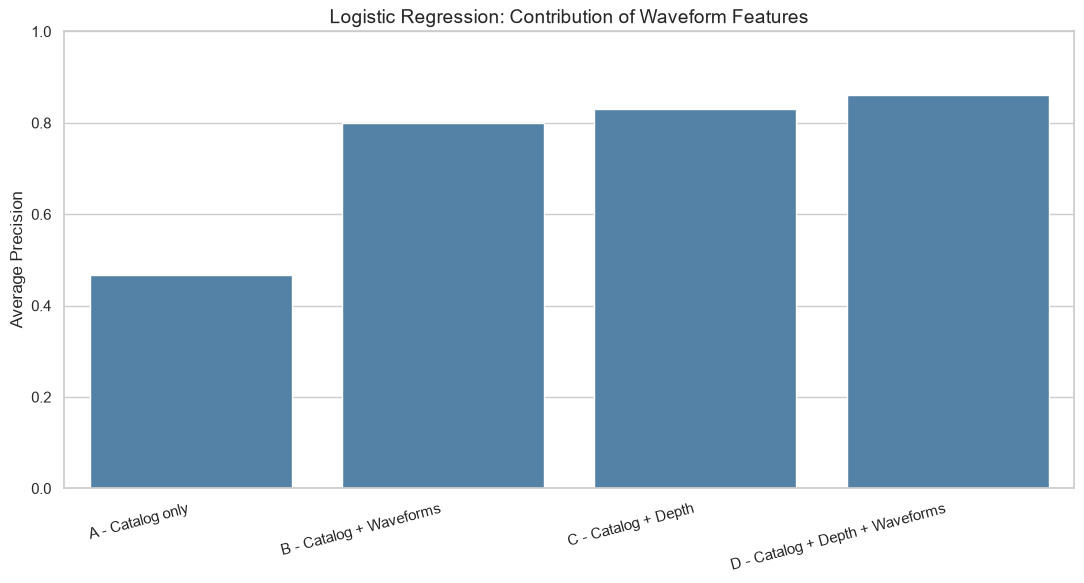

In [34]:
# SECTION 6: PERFORMANCE COMPARISON GRAPH

# Comparing the average precision across the four experiments
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Experiment",
    y="Average Precision",
    color="steelblue"
)

plt.title(
    "Logistic Regression: Contribution of Waveform Features",
    fontsize=14
)
plt.ylabel("Average Precision")
plt.xlabel("")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig("logistic_regression_comparison.png", dpi=300)
plt.show()


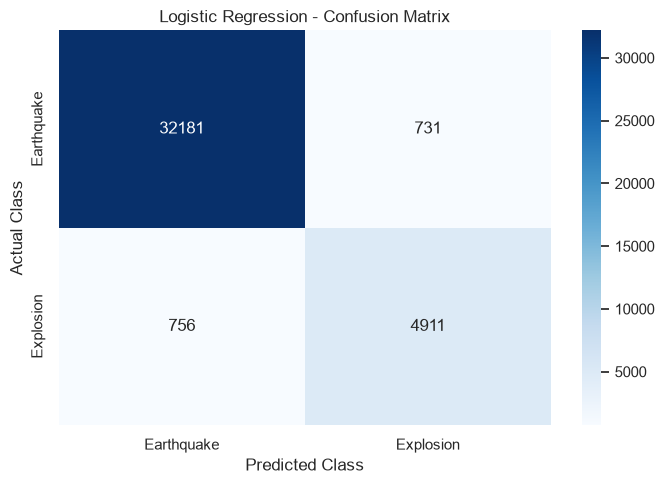

In [35]:
# SECTION 7: CONFUSION MATRIX

# Using the model with catalog, depth and waveform features
best_experiment = "D - Catalog + Depth + Waveforms"

# Converting the predicted probabilities into classes
best_predictions = (
    all_predictions[best_experiment] >= 0.5
).astype(int)

# Calculating the confusion matrix
cm = confusion_matrix(y, best_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Earthquake", "Explosion"],
    yticklabels=["Earthquake", "Explosion"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig("logistic_regression_confusion_matrix.png", dpi=300)
plt.show()


In [36]:
# SECTION 8: EXPORTING THE RESULTS

# Saving the performance comparison
results_df.to_csv(
    "logistic_regression_results.csv",
    index=False
)

# Saving the confusion matrix
pd.DataFrame(
    cm,
    index=["Actual Earthquake", "Actual Explosion"],
    columns=["Predicted Earthquake", "Predicted Explosion"]
).to_csv("logistic_regression_confusion_matrix.csv")

print("Results successfully exported!")


Results successfully exported!
